In [23]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

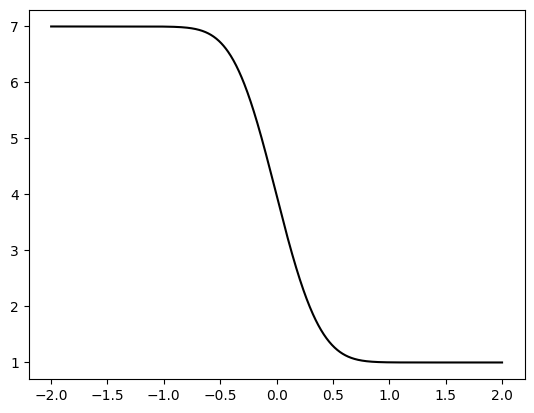

In [24]:
cols = ["x", "rho", "v", "theta", "p", "U300", "U120", "U400", "U220", "U500"]
data = np.loadtxt("bgk_rhoL7.0_Kn1.0.csv", delimiter=",")
ref = {name: data[:, i] for i, name in enumerate(cols)}

data_3V = np.loadtxt("bgk_3V_rhoL7.0_Kn1.0.csv", delimiter=",")
ref_3V = {name: data_3V[:, i] for i, name in enumerate(cols[:-1])}

# e.g. overlay on your moment solution
plt.plot(ref["x"], ref["rho"], "k-", label="BGK reference")

In [25]:
# DVM
rho_L = 7.0
v_L = 0.0
theta_L = 1.0
rho_R = 1.0
v_R = 0.0
theta_R = 1.0
x_lower = -2.0
x_upper = 2.0
Kn = 1.0
source = "relaxation_source"
T_end = 0.3
polydeg = 1
base_tree_level = 10

N = 1_000 
base_tree_level_DVM = 8
x_left_DVM = -5.0
x_right_DVM = 5.0
c_L = -6.0
c_R = 6.0

In [26]:
data_DVM = pd.read_csv(f'../out/Shock/DVM/DVM_solution_N{N}_c_l{c_L}_c_u{c_R}_Kn{Kn}_source{source}_T_end{T_end}_rho_L{rho_L}_rho_R{rho_R}_v_L{v_L}_v_R{v_R}_theta_L{theta_L}_theta_R{theta_R}_base_tree_level{base_tree_level_DVM}_polydeg{polydeg}_x_left{x_left_DVM}_x_right{x_right_DVM}_rho_v_p.csv')

In [27]:
x_DVM = data_DVM['x'].to_numpy()

rho_DVM = data_DVM['rho'].to_numpy()
v_DVM = data_DVM['v'].to_numpy()
p_DVM = data_DVM['p'].to_numpy()
theta_DVM = p_DVM / rho_DVM

/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_54781/3621371650.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_54781/3621371650.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_54781/3621371650.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.show()
/var/folders/mm/p6fstv8949vbtxn89ljjbk8w0000gp/T/ipykernel_54781/3621371650.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); fig.show()


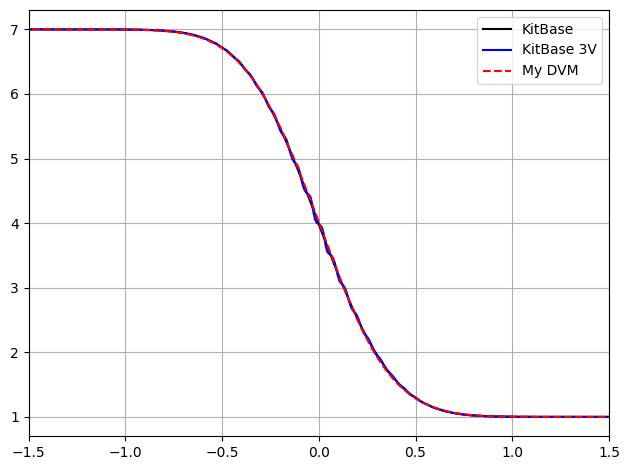

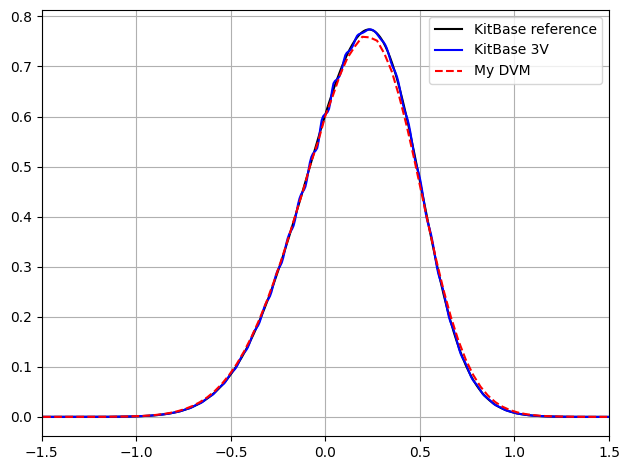

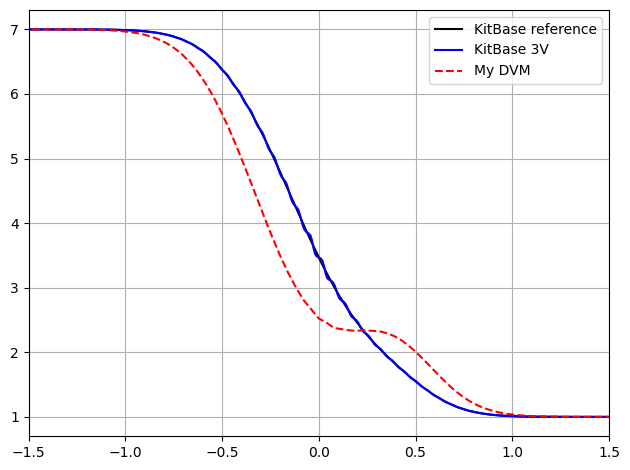

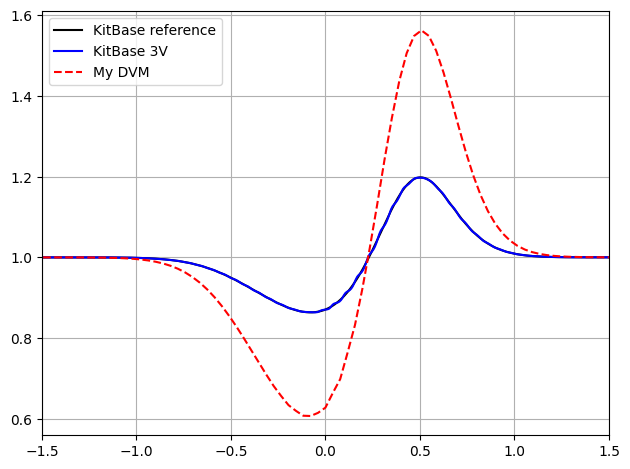

In [28]:
fig, axs = plt.subplots()
axs.plot(ref["x"], ref["rho"], "k-", label="KitBase")
axs.plot(ref_3V["x"], ref_3V["rho"], "b-", label="KitBase 3V")
axs.plot(x_DVM, rho_DVM, "r--", label="My DVM")
axs.legend(); axs.grid(); axs.set_xlim(-1.5, 1.5)
fig.tight_layout(); fig.show()

fig, axs = plt.subplots()
axs.plot(ref["x"], ref["v"], "k-", label="KitBase reference")
axs.plot(ref_3V["x"], ref_3V["v"], "b-", label="KitBase 3V")
axs.plot(x_DVM, v_DVM, "r--", label="My DVM")
axs.legend(); axs.grid(); axs.set_xlim(-1.5, 1.5)
fig.tight_layout(); fig.show()

fig, axs = plt.subplots()
axs.plot(ref["x"], ref["p"], "k-", label="KitBase reference")
axs.plot(ref_3V["x"], ref_3V["p"], "b-", label="KitBase 3V")
axs.plot(x_DVM, p_DVM, "r--", label="My DVM")
axs.legend(); axs.grid(); axs.set_xlim(-1.5, 1.5)
fig.tight_layout(); fig.show()

fig, axs = plt.subplots()
axs.plot(ref["x"], ref["theta"], "k-", label="KitBase reference")
axs.plot(ref_3V["x"], ref_3V["theta"], "b-", label="KitBase 3V")
axs.plot(x_DVM, theta_DVM, "r--", label="My DVM")
axs.legend(); axs.grid(); axs.set_xlim(-1.5, 1.5)
fig.tight_layout(); fig.show()